<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter3/pendulum_bug_small_angle_max.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



Normalized Maximum Pendulum Angle as the Bug Crawls Outward (slow bug, small angle approximation).



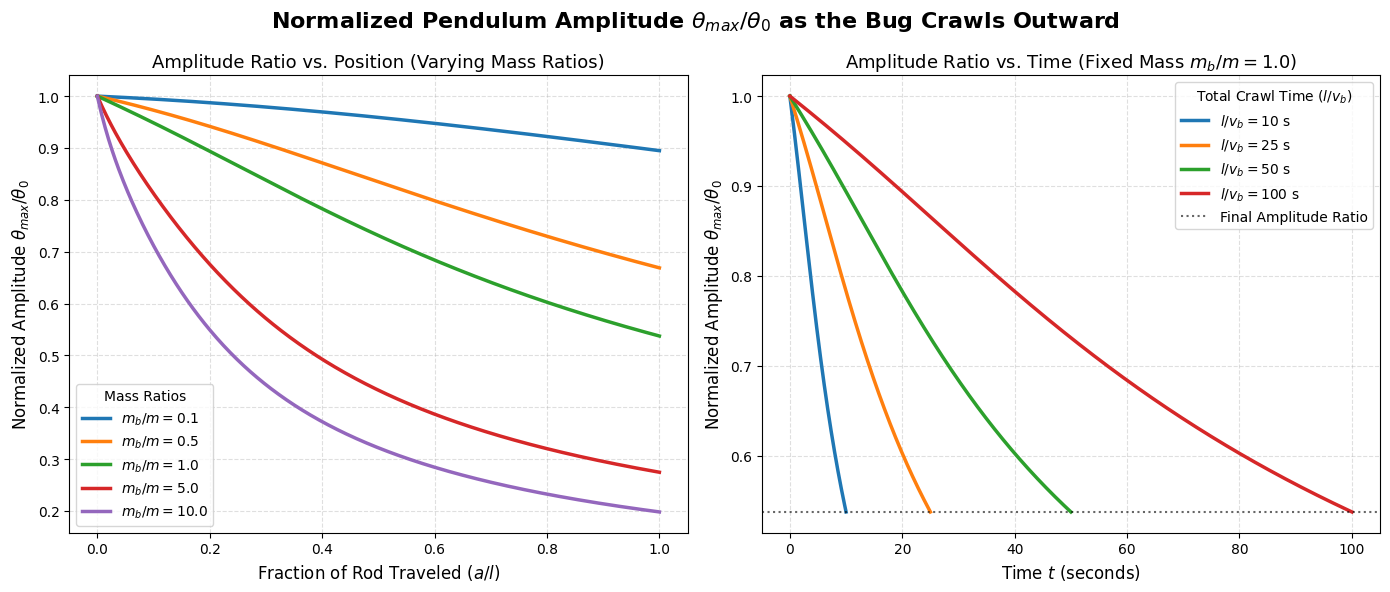

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def calc_theta_ratio(a, m, m_b, l):
    """
    Calculates the adiabatic amplitude ratio of the pendulum as a function of bug position a.
    Based on the derived formula:
    theta_max(a) / theta_0 = [ (1/6 * m^2 * l^3) / (I(a) * (m*l/2 + m_b*a)) ]^(1/4)
    """
    # Cap the bug's position at the end of the rod (a <= l)
    a = np.minimum(a, l)

    # Numerator constant: I(0) * (kappa(0)/g)
    num = (1.0 / 6.0) * (m**2) * (l**3)

    # Denominator variable: I(a) * (kappa(a)/g)
    inertia_a = (1.0 / 3.0) * m * (l**2) + m_b * (a**2)
    kappa_no_g_a = m * (l / 2.0) + m_b * a
    den = inertia_a * kappa_no_g_a

    # Adiabatic amplitude ratio
    return (num / den)**0.25

if __name__ == "__main__":
    # Base dimensional parameters
    l = 1.0          # length of rod in meters
    m = 1.0          # mass of rod in kg

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle('Normalized Pendulum Amplitude $\\theta_{max}/\\theta_0$ as the Bug Crawls Outward', fontsize=16, weight='bold')

    # ==========================================
    # Plot 1: Varying Mass Ratio (m_b / m) plotted vs Position 'a/l'
    # ==========================================
    # We sweep the position 'a' directly from 0 to l
    a_vals = np.linspace(0, l, 500)

    # Mass ratios to test
    mass_ratios = [0.1, 0.5, 1.0, 5.0, 10.0]

    for mb_ratio in mass_ratios:
        m_b = mb_ratio * m
        theta_ratio = calc_theta_ratio(a_vals, m, m_b, l)
        # Plot against normalized position a/l
        ax1.plot(a_vals / l, theta_ratio, linewidth=2.5, label=f'$m_b/m = {mb_ratio}$')

    ax1.set_title('Amplitude Ratio vs. Position (Varying Mass Ratios)', fontsize=13)
    ax1.set_xlabel('Fraction of Rod Traveled ($a/l$)', fontsize=12)
    ax1.set_ylabel('Normalized Amplitude $\\theta_{max}/\\theta_0$', fontsize=12)
    ax1.grid(True, alpha=0.4, linestyle='--')
    ax1.legend(title='Mass Ratios', fontsize=10)

    # ==========================================
    # Plot 2: Varying Speed Ratio (l / v_b) plotted vs Absolute Time 't'
    # ==========================================
    # Fix mass ratio to equal masses (m_b / m = 1.0)
    m_b_fixed = 1.0 * m

    # Total crawl time ratios to test (l / v_b)
    time_ratios = [10, 25, 50, 100]

    for t_ratio in time_ratios:
        v_b = l / t_ratio
        t2 = np.linspace(0, t_ratio, 500)

        # Calculate position 'a' based on time 't' and speed 'v_b'
        a_from_t = v_b * t2

        theta_ratio = calc_theta_ratio(a_from_t, m, m_b_fixed, l)

        # We plot against absolute time t to show how the amplitude drops at different rates
        ax2.plot(t2, theta_ratio, linewidth=2.5, label=f'$l/v_b = {t_ratio}$ s')

    # Mark that they all end up at the exact same final amplitude regardless of speed!
    final_theta_ratio = calc_theta_ratio(l, m, m_b_fixed, l)
    ax2.axhline(final_theta_ratio, color='black', linestyle=':', alpha=0.6, label='Final Amplitude Ratio')

    ax2.set_title(f'Amplitude Ratio vs. Time (Fixed Mass $m_b/m = 1.0$)', fontsize=13)
    ax2.set_xlabel('Time $t$ (seconds)', fontsize=12)
    ax2.set_ylabel('Normalized Amplitude $\\theta_{max}/\\theta_0$', fontsize=12)
    ax2.grid(True, alpha=0.4, linestyle='--')
    ax2.legend(title='Total Crawl Time ($l/v_b$)', fontsize=10)

    plt.tight_layout()
    plt.show()